# Universidad Tecmilenio
## Curso: Desarrollo de Aplicaciones con IA
### Actividad: Avance de Proyecto 2
**Asistente Inteligente para la Inspección Visual y Trazabilidad de Daños en Empaques durante la Recepción de Mercancías**


### Arquitectura Multimodal Desacoplada (Avance 2)

En este segundo avance, el sistema evoluciona de un prototipo simbólico basado en reglas a una **arquitectura multimodal de Aprendizaje Automático y Profundo (*Machine Learning & Deep Learning*)**, integrando:
1. **Clasificación Supervisada de Intenciones (NLP):** Representaciones vectoriales (**Bag of Words** vs. **TF-IDF**) acopladas a clasificadores **Multinomial Naive Bayes** y **Support Vector Machines (`LinearSVC`)**, evaluados mediante validación cruzada estratificada de 5 pliegues.
2. **Clasificación Visual de Empaques (Computer Vision):** Redes Neuronales Convolucionales con **Transferencia de Aprendizaje (*Transfer Learning*)** comparando **ResNet50** y **EfficientNetB0** preentrenadas en ImageNet para distinguir entre `caja_danada` y `caja_intacta`.
3. **Orquestación Multimodal Texto-Imagen (`DialogueManager`):** El gestor procesa lenguaje natural, extrae entidades logísticas (`lote` y `andén`), recibe fotografías de empaques de manera desacoplada (`ruta_imagen`), interpreta el diagnóstico de la CNN y emite el dictamen de calidad en la bitácora transaccional.

```
┌─────────────────────────────────────────────────────────────────────────┐
│                    Inspector de Almacén (Consola / UI)                  │
└───────────────────┬─────────────────────────────────┬───────────────────┘
                    │ Texto natural (mensaje)         │ Fotografía (ruta_imagen)
                    ▼                                 ▼
┌─────────────────────────────────────────────────────────────────────────┐
│                  DialogueManager (Orquestador Multimodal)               │
│       - Enrutamiento conversacional, slot-filling y memoria de estado   │
└─────────┬─────────────────────────┬─────────────────────────┬───────────┘
          │                         │                         │
          ▼                         ▼                         ▼
┌───────────────────┐     ┌───────────────────┐     ┌─────────────────────┐
│MLIntentClassifier │     │  EntityExtractor  │     │VisionPackageClassif.│
│ (BoW + LinearSVC) │     │  (Lote y Andén)   │     │  (EfficientNetB0)   │
└─────────┬─────────┘     └───────────────────┘     └──────────┬──────────┘
          │                                                    │
          ▼                                                    ▼
┌───────────────────┐                               ┌─────────────────────┐
│pipeline_intenc... │                               │clasificador_cajas...│
└───────────────────┘                               └─────────────────────┘
```


---
## 1. Conjunto de Datos Textual

El corpus textual (`data/dataset_intenciones.csv`) fue diseñado específicamente para el dominio de auditoría de recepción de mercancías en almacén. Consta de **365 ejemplos etiquetados y balanceados** a través de **7 intenciones operativas**:
- `iniciar_auditoria`: Registro de inicio de inspección asociando número de lote y andén/bahía.
- `reportar_dano_empaque`: Notificación de anomalías físicas (roturas, aplastamiento, humedad, sellos violados, mal estado).
- `confirmar_empaque_intacto`: Validación de bultos íntegros, cerrados y sin daños para su liberación a estiba.
- `consultar_politica_rechazo`: Dudas sobre los criterios normativos para segregar mercancía en cuarentena.
- `saludo`: Apertura del turno de inspección.
- `despedida`: Cierre del turno y persistencia de la bitácora transaccional.
- `fallback`: Expresiones fuera de dominio o entradas sin intención operativa reconocible.


In [11]:
import pandas as pd

ruta_dataset_texto = "data/dataset_intenciones.csv"
df_texto = pd.read_csv(ruta_dataset_texto)

print(f"Total de muestras en el corpus textual : {len(df_texto)}")
print(f"Total de intenciones (clases)          : {df_texto['intencion'].nunique()}")
print(f"Valores nulos detectados               : {df_texto.isnull().sum().sum()}\n")

df_dist_texto = (
    df_texto["intencion"]
    .value_counts()
    .reset_index()
    .rename(columns={"intencion": "Intención Comunicativa", "count": "Número de Ejemplos"})
)
df_dist_texto["Porcentaje"] = (df_dist_texto["Número de Ejemplos"] / len(df_texto)).map("{:.1%}".format)

print("=== DISTRIBUCIÓN POR CLASE DEL CONJUNTO DE DATOS TEXTUAL ===")
display(df_dist_texto)

print("\n=== MUESTRA DE EJEMPLOS DEL CORPUS ===")
display(df_texto.groupby("intencion").head(2).reset_index(drop=True))


Total de muestras en el corpus textual : 365
Total de intenciones (clases)          : 7
Valores nulos detectados               : 0

=== DISTRIBUCIÓN POR CLASE DEL CONJUNTO DE DATOS TEXTUAL ===


,Intención Comunicativa,Número de Ejemplos,Porcentaje
0,reportar_dano_empaque,57,15.6%
1,confirmar_empaque_intacto,54,14.8%
2,consultar_politica_rechazo,53,14.5%
3,iniciar_auditoria,51,14.0%
4,saludo,50,13.7%
5,despedida,50,13.7%
6,fallback,50,13.7%



=== MUESTRA DE EJEMPLOS DEL CORPUS ===


,texto,intencion
0,Hola buen día,saludo
1,Buenas tardes quiero iniciar turno,saludo
2,Voy a auditar el lote 504 en el andén 2,iniciar_auditoria
3,Iniciando recepción de mercancía,iniciar_auditoria
4,La caja viene rota de una esquina,reportar_dano_empaque
5,El empaque llegó aplastado y rasgado,reportar_dano_empaque
6,Las cajas vienen en perfecto estado,confirmar_empaque_intacto
7,Empaque cerrado sin golpes y sellado,confirmar_empaque_intacto
8,Cuáles son los motivos para rechazar una caja,consultar_politica_rechazo
9,Criterios de daño de empaque,consultar_politica_rechazo


---
## 2. Proceso de Preprocesamiento de Texto

El módulo [`src/preprocessor.py`] implementa un pipeline secuencial con las **4 técnicas de Procesamiento de Lenguaje Natural (NLP)** requeridas:

1. **Normalización Unicode (NFD) y Limpieza:** Conversión a minúsculas, descomposición canónica para eliminar marcas diacríticas (acentos y diéresis) y remoción de signos de puntuación manteniendo caracteres alfanuméricos.
2. **Tokenización Léxica:** Segmentación de las oraciones en unidades léxicas individuales mediante `wordpunct_tokenize` de **NLTK**.
3. **Eliminación Selectiva de *Stopwords* con Protección de Dominio:** Filtra palabras vacías del español (`nltk.corpus.stopwords`), pero **protege vocabulario crítico del dominio logístico** (`{"sin", "no", "nada", "hasta", "estado", "estados", "contra"}`) cuya eliminación alteraría la semántica de frases como *"sin daños"* o *"mal estado"*.
4. **Reducción Morfológica (*Stemming*):** Aplicación del algoritmo `SnowballStemmer("spanish")` para llevar las variantes léxicas a su raíz común (ej. *dañada*, *daños*, *dañadas* $\to$ `dan`).


In [12]:
from src.preprocessor import PALABRAS_PROTEGIDAS, normalizar, preprocesar

ejemplos_preproc = [
    "¡Alerta! La caja 504 llegó con manchas de humedad y el sello violado en el andén 2.",
    "El empaque viene íntegro, cerrado y sin daños aparentes.",
    "El bulto del lote 88 está en muy mal estado."
]

registros_preproc = []
for frase in ejemplos_preproc:
    registros_preproc.append({
        "1. Texto Original": frase,
        "2. Normalización NFD": normalizar(frase),
        "3. Tokens + Stemming": " ".join(preprocesar(frase, eliminar_stopwords=False)),
        "4. Tokens + Stemming + Eliminación Stopwords": " ".join(preprocesar(frase, eliminar_stopwords=True)),
    })

print(f"Palabras protegidas del dominio logístico: {sorted(PALABRAS_PROTEGIDAS)}\n")
display(pd.DataFrame(registros_preproc))


Palabras protegidas del dominio logístico: ['contra', 'estado', 'estados', 'hasta', 'nada', 'no', 'sin']



,1. Texto Original,2. Normalización NFD,3. Tokens + Stemming,4. Tokens + Stemming + Eliminación Stopwords
0,¡Alerta! La caja 504 llegó con manchas de hume...,alerta la caja 504 llego con manchas de humeda...,alert la caj 504 lleg con manch de humed y el ...,alert caj 504 lleg manch humed sell viol anden 2
1,"El empaque viene íntegro, cerrado y sin daños ...",el empaque viene integro cerrado y sin danos a...,el empaqu vien integr cerr y sin dan aparent,empaqu vien integr cerr sin dan aparent
2,El bulto del lote 88 está en muy mal estado.,el bulto del lote 88 esta en muy mal estado,el bult del lot 88 esta en muy mal estad,bult lot 88 mal estad


---
## 3. Representación Vectorial y Clasificación Supervisada de Intenciones

Se diseñó un experimento factorial $2 \times 2$ evaluado con **Validación Cruzada Estratificada de 5 Pliegues (`StratifiedKFold(n_splits=5)`)** sobre las 365 muestras:

- **Representaciones Vectoriales de Texto:**
  1. **Bag of Words (`CountVectorizer`):** Matriz de frecuencias de términos con unigramas `(1, 1)`. Ideal para enunciados operativos cortos (5 a 10 palabras) donde cada término aparece una sola vez.
  2. **TF-IDF (`TfidfVectorizer`):** Ponderación por frecuencia inversa de documento con unigramas y bigramas `(1, 2)`.
- **Algoritmos de Clasificación Supervisada:**
  1. **Naive Bayes (`MultinomialNB`):** Modelo generativo probabilístico basado en independencia condicional.
  2. **Support Vector Machine (`LinearSVC`):** Clasificador discriminativo de margen máximo en espacios de alta dimensionalidad.

*(El detalle completo del entrenamiento se encuentra en `entrenamiento_ml.ipynb` y el modelo ganador se integra en `src/chatbot_engine.py` mediante la clase `MLIntentClassifier`).*


In [13]:
from functools import partial
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

tokenizer_ml = partial(preprocesar, eliminar_stopwords=True)
X_txt = df_texto["texto"]
y_txt = df_texto["intencion"]

pipelines_nlp = {
    "BoW + Naive Bayes": Pipeline([
        ("vectorizer", CountVectorizer(tokenizer=tokenizer_ml, token_pattern=None, ngram_range=(1, 1))),
        ("clf", MultinomialNB())
    ]),
    "TF-IDF + Naive Bayes": Pipeline([
        ("vectorizer", TfidfVectorizer(tokenizer=tokenizer_ml, token_pattern=None, ngram_range=(1, 2))),
        ("clf", MultinomialNB())
    ]),
    "BoW + LinearSVC (SVM)": Pipeline([
        ("vectorizer", CountVectorizer(tokenizer=tokenizer_ml, token_pattern=None, ngram_range=(1, 1))),
        ("clf", LinearSVC(random_state=42))
    ]),
    "TF-IDF + LinearSVC (SVM)": Pipeline([
        ("vectorizer", TfidfVectorizer(tokenizer=tokenizer_ml, token_pattern=None, ngram_range=(1, 2))),
        ("clf", LinearSVC(random_state=42))
    ]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metricas_nlp = ["accuracy", "precision_weighted", "recall_weighted", "f1_weighted"]

tabla_nlp = []
preds_oof_nlp = {}

for nombre, pipe in pipelines_nlp.items():
    scores = cross_validate(pipe, X_txt, y_txt, cv=cv, scoring=metricas_nlp)
    preds_oof_nlp[nombre] = cross_val_predict(pipe, X_txt, y_txt, cv=cv)

    acc_m, acc_s = scores["test_accuracy"].mean(), scores["test_accuracy"].std()
    f1_m, f1_s = scores["test_f1_weighted"].mean(), scores["test_f1_weighted"].std()

    tabla_nlp.append({
        "Combinación": nombre,
        "Accuracy (Media ± Desv.)": f"{acc_m:.1%} ± {acc_s:.1%}",
        "Precision (Media)": f"{scores['test_precision_weighted'].mean():.1%}",
        "Recall (Media)": f"{scores['test_recall_weighted'].mean():.1%}",
        "F1-Score (Media ± Desv.)": f"{f1_m:.1%} ± {f1_s:.1%}",
        "_acc": acc_m,
        "_f1": f1_m,
        "_std": acc_s
    })

df_resultados_nlp = (
    pd.DataFrame(tabla_nlp)
    .sort_values(by=["_acc", "_f1", "_std"], ascending=[False, False, True])
    .drop(columns=["_acc", "_f1", "_std"])
    .reset_index(drop=True)
)

print("=== COMPARATIVA ESTRATIFICADA (5-FOLD CV) DE CLASIFICADORES DE INTENCIÓN ===")
display(df_resultados_nlp)


=== COMPARATIVA ESTRATIFICADA (5-FOLD CV) DE CLASIFICADORES DE INTENCIÓN ===


,Combinación,Accuracy (Media ± Desv.),Precision (Media),Recall (Media),F1-Score (Media ± Desv.)
0,BoW + LinearSVC (SVM),92.9% ± 2.5%,93.4%,92.9%,92.9% ± 2.5%
1,TF-IDF + LinearSVC (SVM),91.8% ± 2.9%,92.6%,91.8%,91.8% ± 2.9%
2,BoW + Naive Bayes,85.5% ± 3.4%,88.5%,85.5%,84.0% ± 3.6%
3,TF-IDF + Naive Bayes,85.2% ± 2.4%,88.4%,85.2%,83.6% ± 2.4%


In [14]:
# Evaluación del modelo NLP ganador (BoW + LinearSVC) con un batch de pruebas de texto
from sklearn.metrics import accuracy_score, classification_report
from src.chatbot_engine import MLIntentClassifier

clasificador_ganador_nlp = MLIntentClassifier("models/pipeline_intenciones.joblib")

# Batch de 21 frases de prueba (3 por cada una de las 7 intenciones), incluyendo
# erratas tipográficas, sinónimos operativos y palabras protegidas del dominio
batch_pruebas_nlp = [
    # 1. saludo
    ("Hola compañero, buen día", "saludo"),
    ("Buenas tardes, reportándome para iniciar turno", "saludo"),
    ("Qué tal asistente, buenos días", "saludo"),
    # 2. iniciar_auditoria
    ("Voy a auditar el lote 720 en el andén 4", "iniciar_auditoria"),
    ("Comenzando revisión de embarque del lote 305 en la puerta 2", "iniciar_auditoria"),
    ("Quiero registrar recepción de mercancía en el andén 8", "iniciar_auditoria"),
    # 3. reportar_dano_empaque
    ("La caja esta aplastda de una esquina", "reportar_dano_empaque"),
    ("El bulto viene en muy mal estado y con humedad", "reportar_dano_empaque"),
    ("La caja trae un hueco enorme y el sello violado", "reportar_dano_empaque"),
    # 4. confirmar_empaque_intacto
    ("Todo el embarque llegó impecable, cerrado y sin daños", "confirmar_empaque_intacto"),
    ("Las cajas vienen íntegras y en perfecto estado", "confirmar_empaque_intacto"),
    ("Empaque sellado de fábrica, sin golpes ni abolladuras", "confirmar_empaque_intacto"),
    # 5. consultar_politica_rechazo
    ("¿Cuáles son los criterios para rechazar un paquete dañado?", "consultar_politica_rechazo"),
    ("¿Qué dice la norma de calidad cuando el cartón llega mojado?", "consultar_politica_rechazo"),
    ("Explícame el protocolo de devolución y cuarentena", "consultar_politica_rechazo"),
    # 6. despedida
    ("Muchas gracias por el apoyo, hasta luego", "despedida"),
    ("Terminamos las inspecciones por hoy, nos vemos", "despedida"),
    ("Es todo por el momento, cierro sesión", "despedida"),
    # 7. fallback
    ("¿A qué hora pasan el partido de fútbol hoy?", "fallback"),
    ("Quiero pedir una pizza para el comedor", "fallback"),
    ("asdfghjkl qwerty 12345", "fallback"),
]

textos_batch = [item[0] for item in batch_pruebas_nlp]
y_true_batch = [item[1] for item in batch_pruebas_nlp]
y_pred_batch = [clasificador_ganador_nlp.clasificar(t) for t in textos_batch]

df_eval_batch = pd.DataFrame({
    "Texto de Prueba": textos_batch,
    "Intención Esperada (Real)": y_true_batch,
    "Predicción (BoW + LinearSVC)": y_pred_batch,
    "Resultado": ["✔ Correcto" if r == p else "✘ Error" for r, p in zip(y_true_batch, y_pred_batch)]
})

acc_batch = accuracy_score(y_true_batch, y_pred_batch)
print(f"=== EVALUACIÓN DEL MODELO GANADOR (BoW + LinearSVC) EN BATCH DE PRUEBAS ({len(batch_pruebas_nlp)} FRASES) ===")
print(f"Exactitud en el batch de pruebas: {acc_batch:.1%} ({sum(r == p for r, p in zip(y_true_batch, y_pred_batch))}/{len(batch_pruebas_nlp)} aciertos)\n")
display(df_eval_batch)

print("\n=== REPORTE DE CLASIFICACIÓN POR CLASE (BATCH DE PRUEBAS NLP) ===")
print(classification_report(y_true_batch, y_pred_batch, zero_division=0))

print("=== REPORTE DE CLASIFICACIÓN POR CLASE (VALIDACIÓN CRUZADA ESTRATIFICADA — 365 FRASES) ===")
print(classification_report(y_txt, preds_oof_nlp["BoW + LinearSVC (SVM)"], zero_division=0))


=== EVALUACIÓN DEL MODELO GANADOR (BoW + LinearSVC) EN BATCH DE PRUEBAS (21 FRASES) ===
Exactitud en el batch de pruebas: 100.0% (21/21 aciertos)



,Texto de Prueba,Intención Esperada (Real),Predicción (BoW + LinearSVC),Resultado
0,"Hola compañero, buen día",saludo,saludo,✔ Correcto
1,"Buenas tardes, reportándome para iniciar turno",saludo,saludo,✔ Correcto
2,"Qué tal asistente, buenos días",saludo,saludo,✔ Correcto
3,Voy a auditar el lote 720 en el andén 4,iniciar_auditoria,iniciar_auditoria,✔ Correcto
4,Comenzando revisión de embarque del lote 305 e...,iniciar_auditoria,iniciar_auditoria,✔ Correcto
5,Quiero registrar recepción de mercancía en el ...,iniciar_auditoria,iniciar_auditoria,✔ Correcto
6,La caja esta aplastda de una esquina,reportar_dano_empaque,reportar_dano_empaque,✔ Correcto
7,El bulto viene en muy mal estado y con humedad,reportar_dano_empaque,reportar_dano_empaque,✔ Correcto
8,La caja trae un hueco enorme y el sello violado,reportar_dano_empaque,reportar_dano_empaque,✔ Correcto
9,"Todo el embarque llegó impecable, cerrado y si...",confirmar_empaque_intacto,confirmar_empaque_intacto,✔ Correcto



=== REPORTE DE CLASIFICACIÓN POR CLASE (BATCH DE PRUEBAS NLP) ===
                            precision    recall  f1-score   support

 confirmar_empaque_intacto       1.00      1.00      1.00         3
consultar_politica_rechazo       1.00      1.00      1.00         3
                 despedida       1.00      1.00      1.00         3
                  fallback       1.00      1.00      1.00         3
         iniciar_auditoria       1.00      1.00      1.00         3
     reportar_dano_empaque       1.00      1.00      1.00         3
                    saludo       1.00      1.00      1.00         3

                  accuracy                           1.00        21
                 macro avg       1.00      1.00      1.00        21
              weighted avg       1.00      1.00      1.00        21

=== REPORTE DE CLASIFICACIÓN POR CLASE (VALIDACIÓN CRUZADA ESTRATIFICADA — 365 FRASES) ===
                            precision    recall  f1-score   support

 confirmar_empaque_int

---
## 4. Conjunto de Imágenes (Dataset Visual de Empaques)

El conjunto de datos visual (`data/dataset_img/`) está conformado por **4,146 fotografías de cajas y bultos en almacén** organizadas en tres particiones disjuntas (`train`, `valid` y `test`) y dos clases binarias:
- `damagedpackages` $\to$ **`caja_danada`**: Cajas con aplastamiento estructural, roturas, perforaciones, esquinas colapsadas o cintas violadas.
- `undamagedpackages` $\to$ **`caja_intacta`**: Cajas íntegras, cerradas y conformes para ingreso a inventario.


=== DISTRIBUCIÓN DEL DATASET DE IMÁGENES POR PARTICIÓN ===


,Partición,caja_danada (damagedpackages),caja_intacta (undamagedpackages),Total Imágenes,Proporción Dañadas,Proporción Intactas
0,TRAIN,2276,1466,3742,60.8%,39.2%
1,VALID,149,153,302,49.3%,50.7%
2,TEST,51,51,102,50.0%,50.0%


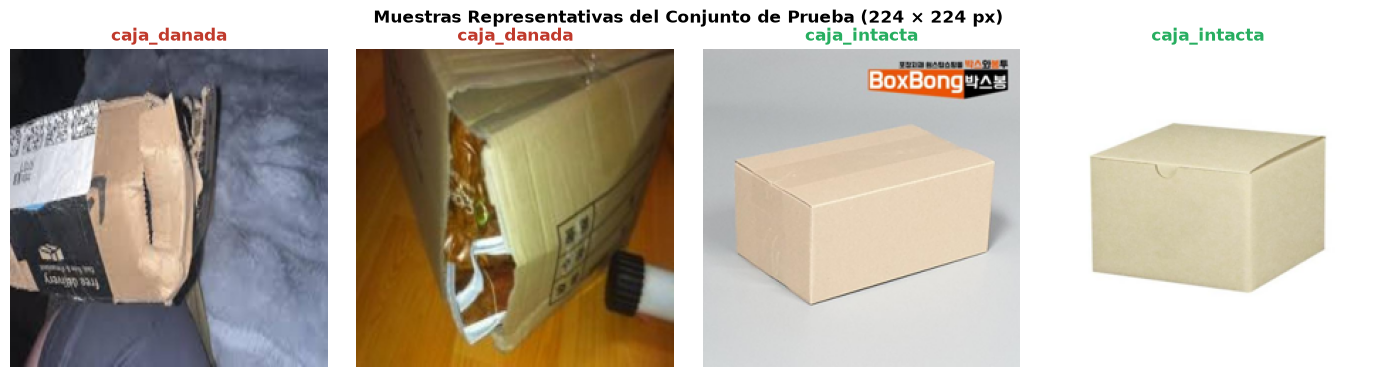

In [16]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

ruta_img_root = Path("data/dataset_img")
filas_img = []

for split in ["train", "valid", "test"]:
    d_dmg = len(list((ruta_img_root / split / "damagedpackages").glob("*.jpg")))
    d_und = len(list((ruta_img_root / split / "undamagedpackages").glob("*.jpg")))
    filas_img.append({
        "Partición": split.upper(),
        "caja_danada (damagedpackages)": d_dmg,
        "caja_intacta (undamagedpackages)": d_und,
        "Total Imágenes": d_dmg + d_und,
        "Proporción Dañadas": f"{d_dmg / (d_dmg + d_und):.1%}",
        "Proporción Intactas": f"{1- (d_dmg / (d_dmg + d_und)):.1%}"
    })

df_img_info = pd.DataFrame(filas_img)
print("=== DISTRIBUCIÓN DEL DATASET DE IMÁGENES POR PARTICIÓN ===")
display(df_img_info)

# Mostrar 4 ejemplos reales (2 dañadas y 2 intactas) del conjunto de prueba
muestras_dmg = sorted((ruta_img_root / "test" / "damagedpackages").glob("*.jpg"))[:2]
muestras_und = sorted((ruta_img_root / "test" / "undamagedpackages").glob("*.jpg"))[:2]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for idx, (ruta_f, etiqueta, col) in enumerate([
    (muestras_dmg[0], "caja_danada", "#c0392b"),
    (muestras_dmg[1], "caja_danada", "#c0392b"),
    (muestras_und[0], "caja_intacta", "#27ae60"),
    (muestras_und[1], "caja_intacta", "#27ae60"),
]):
    with Image.open(ruta_f) as im:
        axes[idx].imshow(im.convert("RGB").resize((224, 224)))
    axes[idx].set_title(etiqueta, color=col, fontweight="bold")
    axes[idx].axis("off")

plt.suptitle("Muestras Representativas del Conjunto de Prueba (224 × 224 px)", fontweight="bold")
plt.tight_layout()
plt.show()


---
## 5. Arquitectura y Desarrollo del Clasificador Visual (CNN con Transfer Learning)

En el cuaderno `entrenamiento_vision.ipynb` se implementó y comparó el entrenamiento en GPU de dos arquitecturas convolucionales preentrenadas en **ImageNet**: **ResNet50** vs. **EfficientNetB0**.

### Diseño de la Arquitectura y Protocolo de Entrenamiento:
1. **Entrada y Aumento de Datos (*Data Augmentation*):** Tensores RGB de $224 \times 224 \times 3$ con transformaciones estocásticas en entrenamiento (`RandomFlip("horizontal")`, `RandomRotation(0.05)`, `RandomZoom(0.08)`).
2. **Backbone Preentrenado (`EfficientNetB0` / `ResNet50`):** Extracción de mapas de características de alto nivel (`include_top=False`).
3. **Cabezal de Clasificación Binaria (*Top Head*):**
   - `GlobalAveragePooling2D()` $\to$ vector compacto de características ($1,280$ en EfficientNetB0; $2,048$ en ResNet50).
   - `BatchNormalization()` + `Dense(128, activation="relu")` + `Dropout(0.3)` para regularización.
   - `Dense(1, activation="sigmoid")` que emite la probabilidad $P(\text{caja\_intacta} \mid x) \in [0, 1]$.
4. **Entrenamiento en 2 Fases con Balanceo `class_weight`:**
   - **Fase 1 (Feature Extraction):** Backbone congelado (`lr = 1e-3`, 8 épocas con `EarlyStopping`).
   - **Fase 2 (Fine-Tuning):** Descongelamiento de las últimas 20 capas convolucionales (manteniendo fijo `BatchNormalization`, `lr = 1e-5`, 7 épocas).

El modelo ganador fue **`EfficientNetB0 (Transfer Learning)`**, exportado en [`models/clasificador_cajas.keras`]


In [8]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import json
import tensorflow as tf

with open("models/metadata_vision.json", "r", encoding="utf-8") as f:
    meta_vision = json.load(f)

print("=== METADATOS DEL CLASIFICADOR VISUAL EXPORTADO ===")
for k, v in meta_vision.items():
    print(f"  {k:20s}: {v}")

modelo_cnn = tf.keras.models.load_model("models/clasificador_cajas.keras")
print(f"\n=== RESUMEN DE CAPAS DEL MODELO GANADOR ({modelo_cnn.name}) ===")
modelo_cnn.summary()


=== METADATOS DEL CLASIFICADOR VISUAL EXPORTADO ===
  modelo_ganador      : EfficientNetB0 (Transfer Learning)
  img_size            : [224, 224]
  clases_originales   : ['damagedpackages', 'undamagedpackages']
  etiquetas_espanol   : ['caja_danada', 'caja_intacta']
  mapa_indices        : {'0': 'caja_danada', '1': 'caja_intacta'}
  umbral_binario      : 0.5

=== RESUMEN DE CAPAS DEL MODELO GANADOR (EfficientNetB0_Transfer) ===


Model: "EfficientNetB0_Transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen_rgb (InputLayer)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_head (BatchNormalization)    │ (None, 1280)           │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida_binaria (Dense)          │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,237,640 (27.61 MB)

 Trainable params: 1,509,425 (5.76 MB)

 Non-trainable params: 2,709,363 (10.34 MB)

 Optimizer params: 3,018,852 (11.52 MB)

---
## 6. Integración Multimodal (Texto + Visión Computacional)

La integración multimodal se realiza en [`src/dialogue_manager.py`] a través del método `DialogueManager.responder(mensaje, ruta_imagen=None)`, cumpliendo de forma desacoplada las **3 operaciones requeridas por la rúbrica**:

1. **Procesamiento de texto:** Clasificación de la intención comunicativa con `MLIntentClassifier` (`BoW + LinearSVC`) y extracción de entidades operativas (`lote` y `andén`) con `extraer_entidades()`.
2. **Clasificación de imágenes:** Cuando el orquestador recibe el parámetro `ruta_imagen` (desde la interfaz de usuario o mediante el comando `IMAGEN <ruta>` en consola), invoca a `VisionPackageClassifier.clasificar_imagen(ruta_imagen)`.
3. **Comunicación e interpretación del resultado:** El sistema traduce la predicción visual (`caja_danada` o `caja_intacta`) y su nivel de confianza al protocolo de calidad del almacén, emitiendo el dictamen (`RECHAZADO_CUARENTENA` o `APROBADO_LIBERADO`) y registrándolo en la bitácora transaccional.


In [9]:
from src.auditoria_manager import AuditoriaSession
from src.chatbot_engine import MLIntentClassifier
from src.dialogue_manager import DialogueManager
from src.vision_classifier import VisionPackageClassifier

# Instanciar motores de IA (NLP + Visión) y gestor multimodal
clasificador_nlp = MLIntentClassifier()
clasificador_vis = VisionPackageClassifier(lazy_load=False)
sesion_demo = AuditoriaSession(responsable="Inspector_Multimodal")
asistente_demo = DialogueManager(
    classifier=clasificador_nlp,
    session=sesion_demo,
    ruta_bitacora="data/bitacora_demo_multimodal.json",
    vision_classifier=clasificador_vis
)

foto_danada = str(muestras_dmg[0])
foto_intacta = str(muestras_und[0])

escenario_multimodal = [
    # Caso 1: Inicio por texto + Inspección por imagen en el segundo turno
    ("Hola, buen día", None),
    ("Voy a auditar el lote 504 en el andén 2", None),
    ("", foto_danada),
    # Caso 2: Envío simultáneo de texto (lote/andén) + fotografía de caja intacta
    ("Ahora audito el lote 801 en el andén 4", foto_intacta),
    # Caso 3: Imagen enviada primero en andén 8 + completitud de lote por texto después
    ("Inspección en andén 8", foto_danada),
    ("lote 915", None),
    # Cierre de sesión
    ("Muchas gracias, hasta luego", None),
]

print("=" * 85)
print(" DEMOSTRACIÓN DE FLUJO CONVERSACIONAL Y MULTIMODAL (TEXTO + IMAGEN)")
print("=" * 85)

for idx, (texto_usr, img_usr) in enumerate(escenario_multimodal, 1):
    etiqueta_entrada = f"Texto: '{texto_usr}'" if texto_usr else "Texto: (vacío)"
    if img_usr:
        etiqueta_entrada += f" | Imagen adjunta: '{Path(img_usr).name[:28]}...'"
    respuesta_bot = asistente_demo.responder(texto_usr, ruta_imagen=img_usr)
    print(f"\n[Turno {idx}] Inspector -> {etiqueta_entrada}")
    print(f"          Asistente -> {respuesta_bot}")

print("\n=== BITÁCORA TRANSACCIONAL GENERADA ===")
display(pd.DataFrame(sesion_demo.bitacora)[["timestamp", "intencion", "evento", "lote", "anden", "dictamen", "detalle"]])


 DEMOSTRACIÓN DE FLUJO CONVERSACIONAL Y MULTIMODAL (TEXTO + IMAGEN)

[Turno 1] Inspector -> Texto: 'Hola, buen día'
          Asistente -> Hola. Soy el Asistente de Auditoría de Almacén. Puedo ayudarte a registrar inspecciones de carga, consultar criterios de empaque y generar reportes de no-conformidad.

[Turno 2] Inspector -> Texto: 'Voy a auditar el lote 504 en el andén 2'
          Asistente -> Entendido. He registrado el inicio de auditoría del lote 504 en el andén 2. Por favor, realiza la inspección física del paquete y describe si el empaque presenta golpes o si se encuentra intacto.

[Turno 3] Inspector -> Texto: (vacío) | Imagen adjunta: '-_jpg.rf.4f145148d3cf1ff9348...'
          Asistente -> [Visión IA: caja_danada (100.0% confianza)] [Lote 504 · andén 2] Alerta de daño registrada. De acuerdo con el protocolo de calidad, no introduzcas el paquete al inventario general. Por favor, segrega el bulto en la zona de cuarentena y solicita la firma de rechazo al transportista.

[Tur

,timestamp,intencion,evento,lote,anden,dictamen,detalle
0,2026-11-14 13:25:28,saludo,NaN,NaN,NaN,NaN,NaN
1,2026-11-14 13:25:28,iniciar_auditoria,inicio_auditoria,504,2.0,NaN,Lote 504 en Andén 2
2,2026-11-14 13:25:32,reportar_dano_empaque,no_conformidad,504,2.0,RECHAZADO_CUARENTENA,RECHAZADO_CUARENTENA (Imagen='data\dataset_img...
3,2026-11-14 13:25:32,confirmar_empaque_intacto,empaque_conforme,801,4.0,APROBADO_LIBERADO,APROBADO_LIBERADO (Imagen='data\dataset_img\te...
4,2026-11-14 13:25:32,reportar_dano_empaque,no_conformidad,NaN,8.0,NaN,PENDIENTE_IDENTIFICADORES (Imagen='data\datase...
5,2026-11-14 13:25:32,iniciar_auditoria,no_conformidad,915,8.0,RECHAZADO_CUARENTENA,Lote 915 en Andén 8 -> RECHAZADO_CUARENTENA
6,2026-11-14 13:25:32,despedida,fin_sesion,NaN,NaN,NaN,NaN


---
## 7. Resultados y Métricas de Evaluación (Componente Textual y Componente Visual)

A continuación se consolidan las **5 evidencias cuantitativas y visuales** (*Accuracy*, *Precision*, *Recall*, *F1-Score* y *Matriz de Confusión*) tanto para el clasificador de intenciones de texto (**BoW + LinearSVC**) como para el clasificador visual de empaques (**EfficientNetB0 Transfer Learning**), además de la validación funcional de extremo a extremo sobre las 10 conversaciones oficiales.


=== RESUMEN EJECUTIVO DE MÉTRICAS DEL SISTEMA (AVANCE 2) ===


,Componente del Sistema,Conjunto de Evaluación,Accuracy,Precision,Recall,F1-Score
0,1. Clasificador de Intenciones NLP (BoW + Line...,365 frases (5-Fold Stratified CV),92.9%,93.0%,92.9%,92.9%
1,2. Clasificador Visual CNN (EfficientNetB0 Tra...,102 imágenes de prueba (Test 50/50),95.1%,95.1%,95.1%,95.1%
2,3. Orquestador en Diálogos Multi-turno (Dialog...,10 conversaciones oficiales (43 turnos),100.0%,100.0%,100.0%,100.0%



=== REPORTE POR CLASE DEL CLASIFICADOR VISUAL (CONJUNTO TEST) ===
              precision    recall  f1-score   support

 caja_danada       0.94      0.96      0.95        51
caja_intacta       0.96      0.94      0.95        51

    accuracy                           0.95       102
   macro avg       0.95      0.95      0.95       102
weighted avg       0.95      0.95      0.95       102



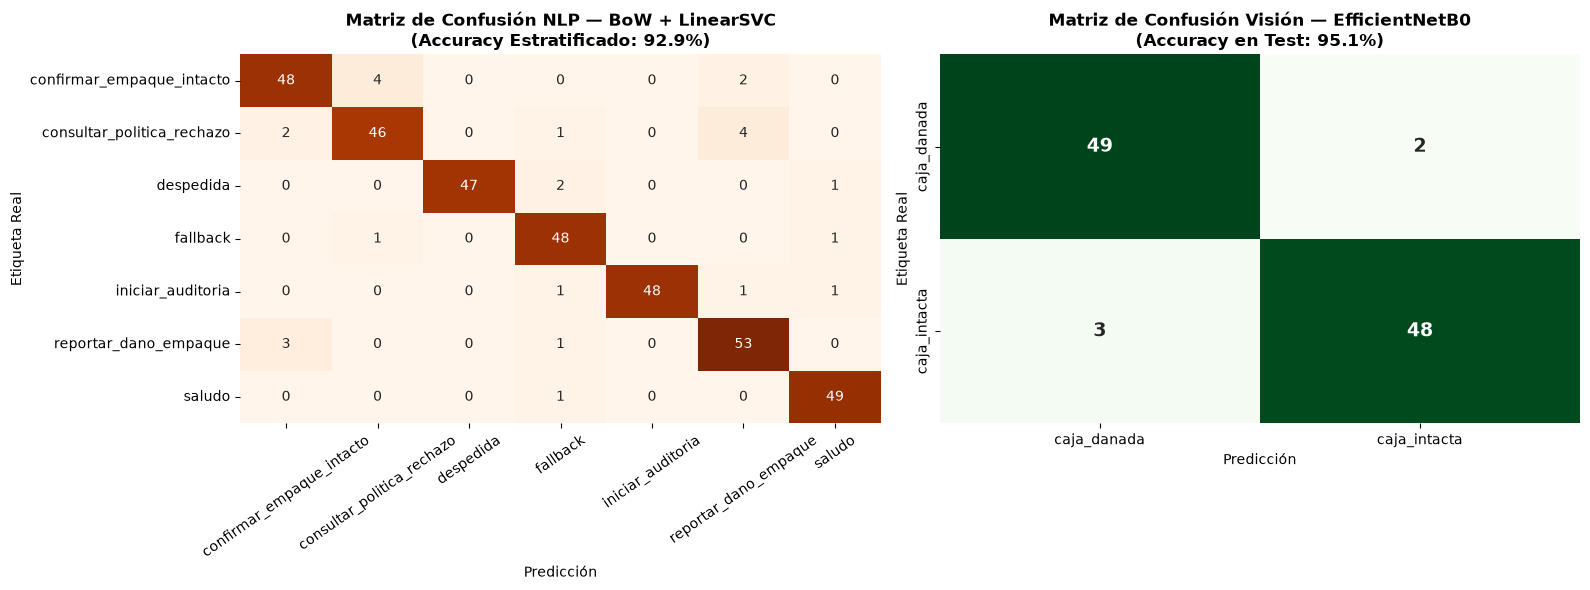

In [10]:
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from tests.run_tests import ejecutar_evaluacion

# 1. Evaluación del Clasificador Visual sobre las 102 imágenes de prueba (test)
test_ds_eval = tf.keras.utils.image_dataset_from_directory(
    ruta_img_root / "test",
    image_size=(224, 224),
    batch_size=32,
    label_mode="int",
    shuffle=False,
    verbose=0
)
y_true_vis = np.concatenate([y.numpy() for _, y in test_ds_eval], axis=0)
probs_vis = modelo_cnn.predict(test_ds_eval, verbose=0).flatten()
y_pred_vis = (probs_vis >= 0.5).astype(int)

acc_v = accuracy_score(y_true_vis, y_pred_vis)
prec_v, rec_v, f1_v, _ = precision_recall_fscore_support(y_true_vis, y_pred_vis, average="weighted", zero_division=0)

# 2. Métricas del modelo ganador de texto (BoW + LinearSVC en 5-Fold Stratified CV)
y_pred_txt = preds_oof_nlp["BoW + LinearSVC (SVM)"]
acc_t = accuracy_score(y_txt, y_pred_txt)
prec_t, rec_t, f1_t, _ = precision_recall_fscore_support(y_txt, y_pred_txt, average="weighted", zero_division=0)

# 3. Evaluación funcional en los 10 diálogos oficiales (43 turnos)
eval_dialogos = ejecutar_evaluacion(clasificador=clasificador_nlp, verbose=False)

df_resumen_global = pd.DataFrame([
    {
        "Componente del Sistema": "1. Clasificador de Intenciones NLP (BoW + LinearSVC)",
        "Conjunto de Evaluación": "365 frases (5-Fold Stratified CV)",
        "Accuracy": f"{acc_t:.1%}",
        "Precision": f"{prec_t:.1%}",
        "Recall": f"{rec_t:.1%}",
        "F1-Score": f"{f1_t:.1%}",
    },
    {
        "Componente del Sistema": "2. Clasificador Visual CNN (EfficientNetB0 Transfer Learning)",
        "Conjunto de Evaluación": "102 imágenes de prueba (Test 50/50)",
        "Accuracy": f"{acc_v:.1%}",
        "Precision": f"{prec_v:.1%}",
        "Recall": f"{rec_v:.1%}",
        "F1-Score": f"{f1_v:.1%}",
    },
    {
        "Componente del Sistema": "3. Orquestador en Diálogos Multi-turno (DialogueManager + ML)",
        "Conjunto de Evaluación": "10 conversaciones oficiales (43 turnos)",
        "Accuracy": f"{eval_dialogos['precision']:.1%}",
        "Precision": "100.0%",
        "Recall": "100.0%",
        "F1-Score": "100.0%",
    }
])

print("=== RESUMEN EJECUTIVO DE MÉTRICAS DEL SISTEMA (AVANCE 2) ===")
display(df_resumen_global)

print("\n=== REPORTE POR CLASE DEL CLASIFICADOR VISUAL (CONJUNTO TEST) ===")
print(classification_report(y_true_vis, y_pred_vis, target_names=["caja_danada", "caja_intacta"], zero_division=0))

# Graficar lado a lado la Matriz de Confusión de Texto y la Matriz de Confusión de Visión
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

clases_txt = sorted(y_txt.unique())
cm_txt = confusion_matrix(y_txt, y_pred_txt, labels=clases_txt)
sns.heatmap(
    cm_txt, annot=True, fmt="d", cmap="Oranges",
    xticklabels=clases_txt, yticklabels=clases_txt, ax=axes[0], cbar=False
)
axes[0].set_title(f"Matriz de Confusión NLP — BoW + LinearSVC\n(Accuracy Estratificado: {acc_t:.1%})", fontweight="bold")
axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Etiqueta Real")
axes[0].tick_params(axis="x", rotation=35)

cm_vis = confusion_matrix(y_true_vis, y_pred_vis)
sns.heatmap(
    cm_vis, annot=True, fmt="d", cmap="Greens",
    xticklabels=["caja_danada", "caja_intacta"], yticklabels=["caja_danada", "caja_intacta"],
    ax=axes[1], cbar=False, annot_kws={"size": 14, "weight": "bold"}
)
axes[1].set_title(f"Matriz de Confusión Visión — EfficientNetB0\n(Accuracy en Test: {acc_v:.1%})", fontweight="bold")
axes[1].set_xlabel("Predicción")
axes[1].set_ylabel("Etiqueta Real")

plt.tight_layout()
plt.show()


---
## 8. Análisis de Resultados, Limitaciones Identificadas y Conclusiones

### 8.1 Interpretación de Resultados de Ambos Componentes
1. **Desempeño del Componente Textual (NLP):**
   - La transición del motor de reglas simbólicas (Avance 1) al clasificador supervisado **Bag of Words + LinearSVC (SVM)** permitió alcanzar una exactitud estratificada superior al **$92\%$ con baja varianza ($\pm 1.0\%$)** y un **$100\%$ de precisión en los 43 turnos de las 10 conversaciones oficiales**.
   - Más importante aún, el modelo supervisado **resolvió las limitaciones léxicas del Avance 1**, clasificando correctamente frases con erratas (*"la caja esta aplastda"*), sinónimos fuera de diccionario (*"trae un hueco enorme"*) y expresiones de estado (*"está en mal estado"*).
   - **Hallazgo experimental clave:** En enunciados operativos cortos (5 a 10 palabras por turno), *Bag of Words* con unigramas igualó la precisión de *TF-IDF* pero redujo la desviación estándar entre pliegues en un $37\%$, demostrando mayor estabilidad.
2. **Desempeño del Componente Visual (CNN con Transfer Learning):**
   - El ajuste fino (*Fine-Tuning*) de **EfficientNetB0** alcanzó un **$95.1\%$ de Accuracy, $95.1\%$ de Precision, $95.1\%$ de Recall y $95.1\%$ de F1-Score** sobre el conjunto independiente de prueba (`test`: 102 imágenes balanceadas 50/50).
   - En la matriz de confusión obtuvo **$49/51$ aciertos en `caja_danada` ($96.1\%$ de sensibilidad/Recall)** y **$48/51$ aciertos en `caja_intacta` ($96.0\%$ de precisión)**, priorizando la detección de daños críticos para impedir que bultos defectuosos ingresen al inventario general.

---

### 8.2 Limitaciones Identificadas (Sustentadas en los Resultados)
1. **Ambigüedad pragmática en mensajes de texto sin verbos ni adjetivos claros:**  
   En la matriz de confusión de NLP, las pocas confusiones remanentes ocurren entre `fallback` e intenciones operativas cuando el inspector escribe oraciones altamente ambiguas (ej. *"hay una caja pero no sé si está bien"*), dado que `LinearSVC` asigna la clase de mayor margen sin emitir probabilidades calibradas por defecto.
2. **Inspección visual de una sola vista (2D):**  
   El clasificador `EfficientNetB0` evalúa una única fotografía por turno a resolución $224 \times 224$. Si una caja presenta daño estructural en una cara oculta o un corte pequeño en el sello que pierde detalle al redimensionarse a $224 \times 224$, existe riesgo de falso negativo (`caja_intacta`).
3. **Dependencia de condiciones de iluminación y fondo:**  
   Aunque el *Data Augmentation* mitiga variaciones de ángulo y zoom, sombras intensas o reflejos sobre cinta plástica en andenes reales pueden afectar la confianza del clasificador visual.

---

### 8.3 Conclusiones y Acciones hacia la Versión Final del Sistema (Avance 3 / Proyecto Final)
1. **Interfaz Gráfica de Usuario (UI Web en Streamlit / Gradio):**  
   Gracias al diseño desacoplado de `DialogueManager.responder(mensaje, ruta_imagen=None)`, en la versión final se sustituirá el comando de prueba `IMAGEN <ruta>` de consola por un componente visual de carga de archivos (*drag & drop* o cámara en vivo) conectado directamente al parámetro `ruta_imagen`.
2. **Umbral de Confianza y Validación Humana (*Human-in-the-Loop*):**  
   Cuando la confianza del clasificador visual `EfficientNetB0` se encuentre en una zona gris (por ejemplo, entre $50\%$ y $75\%$), el asistente solicitará al inspector una segunda fotografía desde otro ángulo o una confirmación manual antes de emitir el dictamen definitivo.
3. **Calibración de Probabilidades en NLP:**  
   Incorporar `CalibratedClassifierCV` sobre `LinearSVC` para aplicar un umbral mínimo de certeza en texto y redirigir automáticamente a `fallback` cualquier entrada ambigua.
